<a href="https://colab.research.google.com/github/kasianeno/online-store-sales-analysis/blob/main/Online_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker

from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/Pandas_tasks/main/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Pandas_tasks/main


In [ ]:
data = pd.read_csv('data.csv')
data.head(100)

,session_date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,medium,channel,account_id,is_verified,is_unsubscribed,item_id,category,name,unit_price,short_description
0,2020-11-12,2931827083,Americas,United States,mobile,Chrome,Pixel 3,Android,en-us,referral,Social Search,636139,1,0,10311228,Beds,KURA,125.0,Bed tent
1,2020-11-15,5498238047,Europe,United Kingdom,mobile,Chrome,Pixel 4 XL,Web,en-us,organic,Organic Search,667330,1,0,39291418,Outdoor furniture,ÄPPLARÖ,841.0,Wall panel+gatleg table+2 chairs
2,2020-11-24,7831502984,Asia,Japan,mobile,Chrome,Pixel 4 XL,Web,en-us,<Other>,Paid Search,648281,1,0,60240035,Outdoor furniture,ASKHOLMEN,149.0,"Table, outdoor, 60x62 cm"
3,2020-11-28,2456603208,Asia,Taiwan,mobile,Chrome,Pixel 3,Web,en-us,<Other>,Paid Search,644225,1,0,19277036,Chairs,MÖCKELBY / FANBYN,4145.0,"Table and 6 chairs, 235x100 cm"
4,2020-11-30,3721704283,Europe,Austria,mobile,Chrome,Pixel 4 XL,Web,en-us,(none),Direct,648377,1,0,19257509,Sofas & armchairs,EKTORP,2345.0,3-seat sofa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2020-11-15,861675394,Americas,Canada,mobile,<Other>,<Other>,Web,NaN,organic,Organic Search,648132,1,0,40344500,Sofas & armchairs,STOCKHOLM 2017,5436.0,Three-seat sofa
96,2020-11-15,4579464218,Americas,United States,mobile,Chrome,<Other>,Web,NaN,referral,Social Search,658150,1,0,39207716,Chairs,JULES,255.0,Children's desk chair
97,2020-11-15,219396375,Americas,United States,mobile,Chrome,<Other>,Android,NaN,(none),Direct,677614,1,0,99014376,Chairs,MELLTORP / ADDE,359.0,"Table and 4 chairs, 125 cm"
98,2020-11-15,8287031945,Americas,United States,mobile,Chrome,<Other>,Web,en,organic,Organic Search,645732,1,1,50397913,Chests of drawers & drawer units,IDÅSEN,595.0,"Drawer unit on castors, 42x61 cm"


In [ ]:
#changing data type
data['session_date'] = pd.to_datetime(data['session_date'])

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2781 entries, 0 to 2780
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   session_date       2781 non-null   datetime64[ns]
 1   session_id         2781 non-null   int64         
 2   continent          2781 non-null   object        
 3   country            2781 non-null   object        
 4   device             2781 non-null   object        
 5   browser            2781 non-null   object        
 6   mobile_model_name  2781 non-null   object        
 7   operating_system   2781 non-null   object        
 8   language           1866 non-null   object        
 9   medium             2781 non-null   object        
 10  channel            2781 non-null   object        
 11  account_id         2781 non-null   int64         
 12  is_verified        2781 non-null   int64         
 13  is_unsubscribed    2781 non-null   int64         
 14  item_id 

In [ ]:
print(f'Missing data count:\n{data.isna().sum()}\n')
print(f'Percentage of missing values:\n{data.isna().sum()/data.shape[0] * 100}')
print(f'\nDuplicates count: {data.duplicated().sum()}')

Missing data count:
session_date           0
session_id             0
continent              0
country                0
device                 0
browser                0
mobile_model_name      0
operating_system       0
language             915
medium                 0
channel                0
account_id             0
is_verified            0
is_unsubscribed        0
item_id                0
category               0
name                   0
unit_price             0
short_description      0
dtype: int64

Percentage of missing values:
session_date          0.000000
session_id            0.000000
continent             0.000000
country               0.000000
device                0.000000
browser               0.000000
mobile_model_name     0.000000
operating_system      0.000000
language             32.901834
medium                0.000000
channel               0.000000
account_id            0.000000
is_verified           0.000000
is_unsubscribed       0.000000
item_id               0.000

In [ ]:
plt.style.use("seaborn-v0_8")

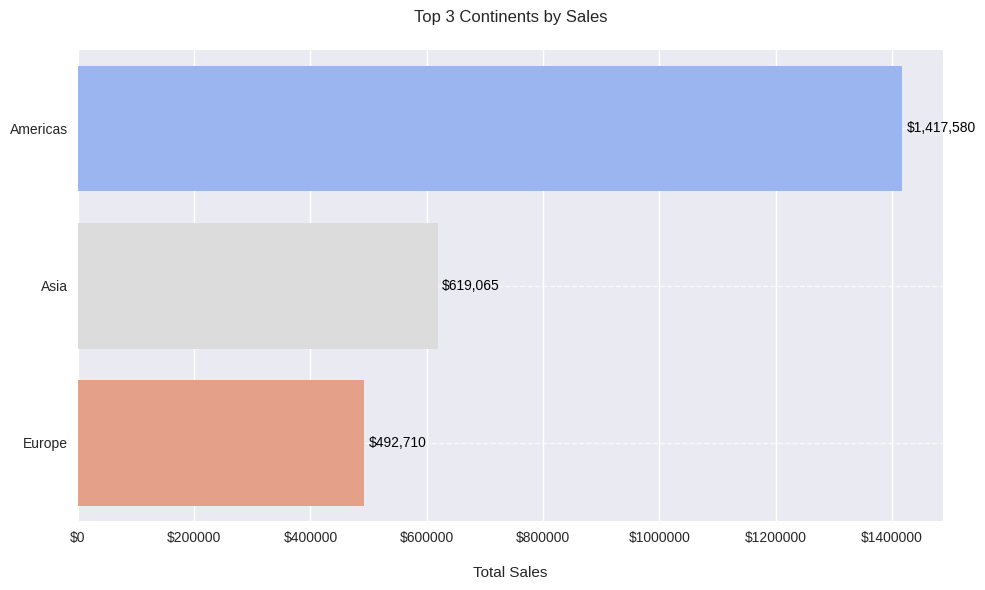

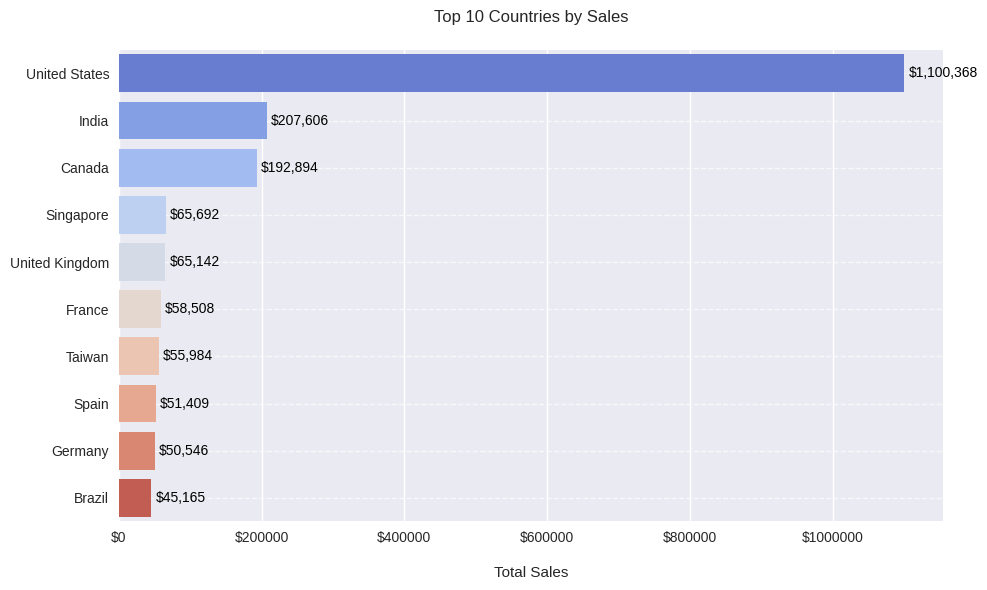

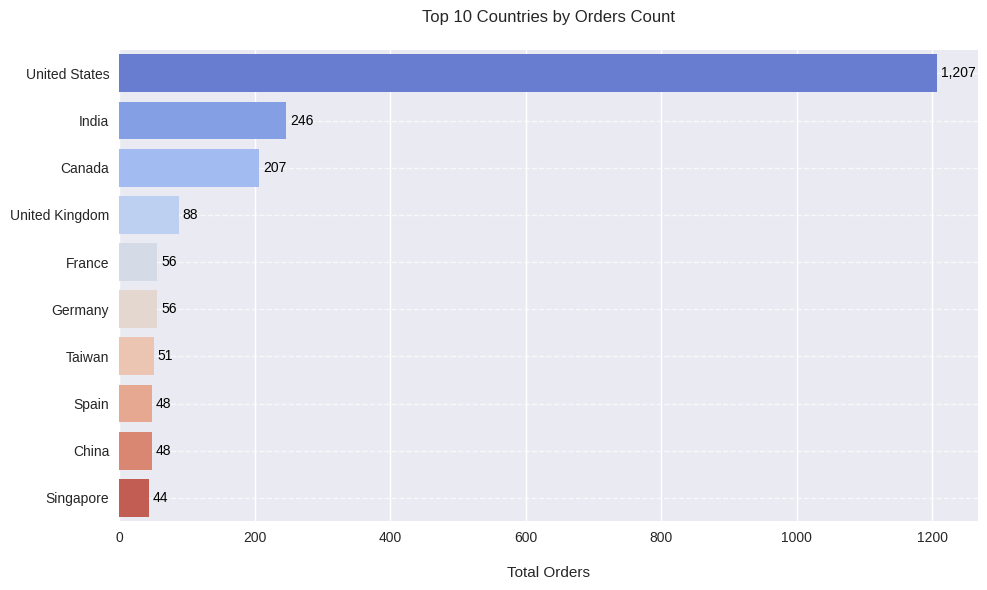

In [ ]:
#sales by continent
sales_by_continent = data.groupby('continent')['unit_price'].sum().sort_values(ascending=False).reset_index()
sales_by_continent = sales_by_continent[sales_by_continent['continent'] != '(not set)']


fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
  data=sales_by_continent.head(3),
  x='unit_price', y='continent', palette='coolwarm', hue='continent', ax=ax, legend=False
)
plt.title('Top 3 Continents by Sales', pad=20)
plt.xlabel('Total Sales', labelpad=15)
plt.ylabel('')
formatter = mticker.FormatStrFormatter('$%.0f')
ax.xaxis.set_major_formatter(formatter)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add unit price labels on the bars
for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}',  padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()

#sales by country
sales_by_country = data.groupby('country')['unit_price'].sum().sort_values(ascending=False).reset_index()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
  data=sales_by_country.head(10),
  x='unit_price', y='country', palette='coolwarm', hue='country', ax=ax, legend=False
)
plt.title('Top 10 Countries by Sales', pad=20)
plt.xlabel('Total Sales', labelpad=15)
plt.ylabel('')
formatter = mticker.FormatStrFormatter('$%.0f')
ax.xaxis.set_major_formatter(formatter)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add unit price labels on the bars
for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}',  padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()


# top countries by order count
order_count_by_country = data.groupby('country')['session_id'].count().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
  data=order_count_by_country.head(10),
  x='session_id', y='country', palette='coolwarm', hue='country', ax=ax, legend=False
)
plt.title('Top 10 Countries by Orders Count', pad=20)
plt.xlabel('Total Orders', labelpad=15)
plt.ylabel('')
formatter = mticker.FormatStrFormatter('%.0f')
ax.xaxis.set_major_formatter(formatter)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add unit price labels on the bars
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}',  padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()

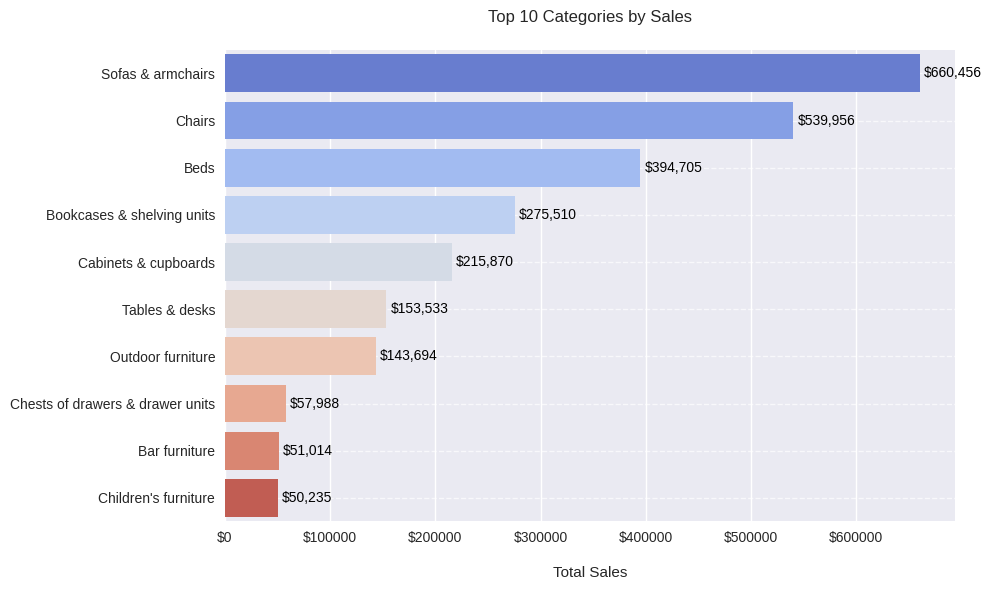

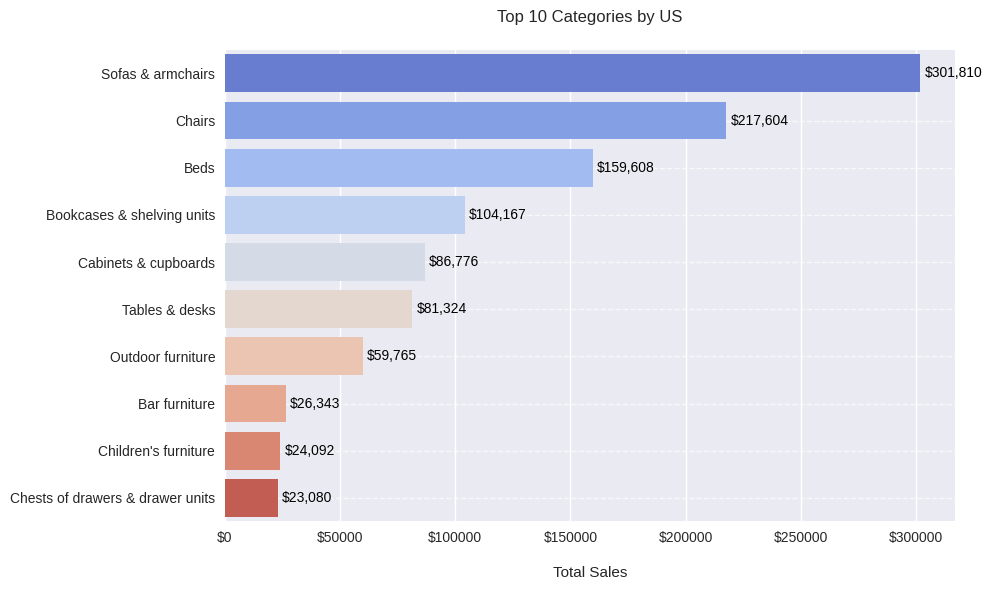

In [ ]:
#top10 categories by sales
sales_by_category = data.groupby('category')['unit_price'].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
  data=sales_by_category.head(10),
  x='unit_price',
  y='category', palette='coolwarm', hue='category', ax=ax, legend=False
)

plt.title('Top 10 Categories by Sales', pad=20)
plt.xlabel('Total Sales', labelpad=15)
plt.ylabel('')
formatter = mticker.FormatStrFormatter('$%.0f')
ax.xaxis.set_major_formatter(formatter)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}',  padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()

#top10 categories in United States
sales_by_category_usa = data[data['country'] == 'United States'].groupby('category')['unit_price'].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
  data=sales_by_category_usa.head(10),
  x='unit_price',
  y='category', palette='coolwarm', hue='category', ax=ax, legend=False
)

plt.title('Top 10 Categories by US', pad=20)
plt.xlabel('Total Sales', labelpad=15)
plt.ylabel('')
formatter = mticker.FormatStrFormatter('$%.0f')
ax.xaxis.set_major_formatter(formatter)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}',  padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()


*Overall, there are some differences in the top categories when we compare the country with the highest sales and the global situation. The category chest and drawers got better placement in the US, ranked up from the bottom to the 7th placement .*

In [ ]:
#sales by device type and device model
total_sales = data['unit_price'].sum()

sales_by_device = data.groupby('device')['unit_price'].sum().sort_values(ascending=False).reset_index()
sales_by_device['%_of_total'] = (sales_by_device['unit_price'] / total_sales * 100).round(1)
display(sales_by_device)

sales_by_device_model = data.groupby(['device', 'mobile_model_name'])['unit_price'].sum().sort_values(ascending=False).reset_index()
sales_by_device_model['%_of_total'] = (sales_by_device_model['unit_price'] / total_sales * 100).round(1)

display(sales_by_device_model.head(10))


,device,unit_price,%_of_total
0,desktop,1481011.4,57.3
1,mobile,1039518.0,40.3
2,tablet,61989.1,2.4


,device,mobile_model_name,unit_price,%_of_total
0,desktop,Chrome,741986.0,28.7
1,mobile,iPhone,558733.2,21.6
2,desktop,Safari,498233.7,19.3
3,mobile,<Other>,464138.8,18.0
4,desktop,ChromeBook,125058.1,4.8
5,desktop,Edge,49389.0,1.9
6,tablet,iPad,40568.1,1.6
7,desktop,<Other>,37179.6,1.4
8,desktop,Firefox,29165.0,1.1
9,tablet,<Other>,21421.0,0.8


*The most popular device type by sales is desktop, with Chrome as the most common device model.*

In [ ]:
#sales by traffic channel

sales_by_channel = data.groupby('channel')['unit_price'].sum().sort_values(ascending=False).reset_index()
sales_by_channel['%_of_total'] = (sales_by_channel['unit_price'] / total_sales * 100).round(2)

display(sales_by_channel.head(3))

,channel,unit_price,%_of_total
0,Organic Search,934329.5,36.18
1,Paid Search,640799.6,24.81
2,Direct,608937.2,23.58


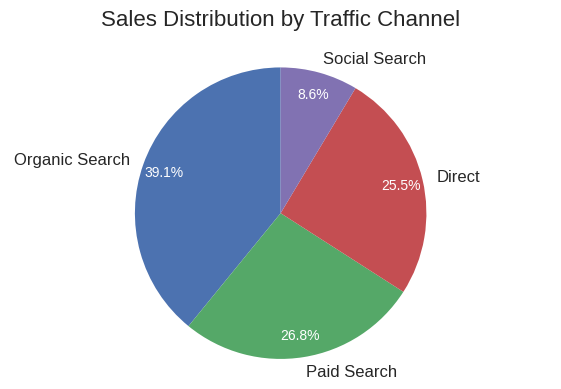

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

# Filter out any '(not set)' or similar categories if present, or just directly plot if confident in data
pie_data = sales_by_channel[sales_by_channel['channel'] != 'Undefined']

# Create the pie chart
wedges, texts, autotexts = ax.pie(
    pie_data['unit_price'],
    labels=pie_data['channel'],
    autopct='%1.1f%%', # Format percentages to one decimal place
    startangle=90, # Start the first slice at the top
    pctdistance=0.85, # Distance of percentage labels from the center
    textprops={'fontsize': 12}, # Font size for labels
)

# Adjust autopct text properties for better readability
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(10)

ax.set_title('Sales Distribution by Traffic Channel', fontsize=16, pad=20)
ax.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.

plt.tight_layout()
plt.show()

In [ ]:
#percent of approved emails verifications by subscribers.
data['is_approved'] = np.where((data['is_unsubscribed'] == 0) & (data['is_verified'] == 1), 'Verified', 'Not Verified')
(data['is_approved'].value_counts() / data.is_verified.count() * 100).round(2)



,count
is_approved,
Verified,57.03
Not Verified,42.97


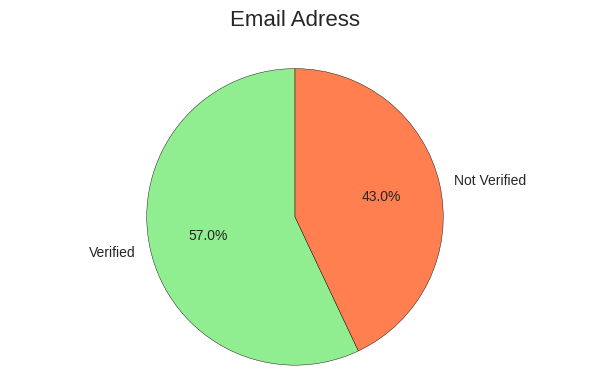

In [ ]:
approved_counts = data['is_approved'].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
ax.pie(
    approved_counts,
    labels=approved_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightgreen', 'coral'],
    wedgeprops={'edgecolor': 'black'}
)

ax.set_title('Email Adress', fontsize=16, pad=20)
ax.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.

plt.tight_layout()
plt.show()

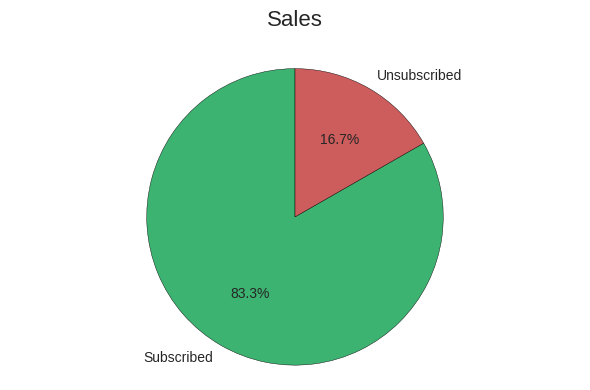

In [ ]:
#sales by subscribed and unsubscribed users
sales_by_status = data.groupby('is_unsubscribed')['unit_price'].sum().reset_index()

sales_by_sub = sales_by_status[sales_by_status['is_unsubscribed'] == 0].sort_values(by='unit_price', ascending=False).reset_index(drop=True)
sales_by_unsub = sales_by_status[sales_by_status['is_unsubscribed'] == 1].sort_values(by='unit_price', ascending=False).reset_index(drop=True)
sub_sales_per = sales_by_sub.unit_price / total_sales *100
unsub_sales_per = sales_by_unsub.unit_price / total_sales *100

sales_percentages = pd.Series({
    'Subscribed': sub_sales_per.iloc[0],
    'Unsubscribed': unsub_sales_per.iloc[0]
})

fig, ax = plt.subplots(figsize=(6, 4))
ax.pie(
    sales_percentages,
    labels=sales_percentages.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['mediumseagreen', 'indianred'],
    wedgeprops={'edgecolor': 'black'}
)

ax.set_title('Sales', fontsize=16, pad=20)
ax.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.

plt.tight_layout()
plt.show()


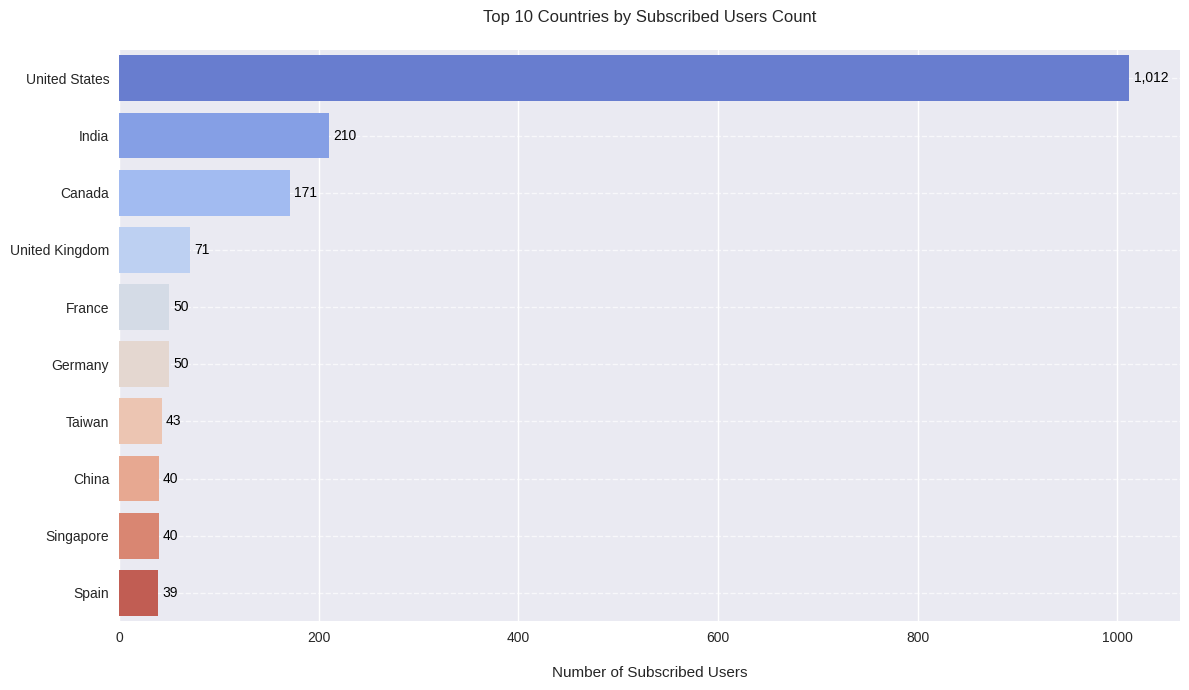

In [ ]:
#subscribed users count by country
sub_users_by_country = data[data['is_unsubscribed'] == 0].groupby('country')['session_id'].count().reset_index().sort_values(by='session_id', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=sub_users_by_country.head(10),
    x='session_id',
    y='country',
    palette='coolwarm',
    hue='country',
    ax=ax,
    legend=False
)

plt.title('Top 10 Countries by Subscribed Users Count', pad=20)
plt.xlabel('Number of Subscribed Users', labelpad=15)
plt.ylabel('')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()

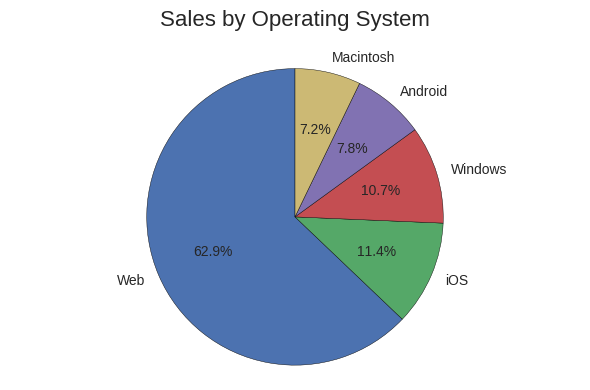

In [ ]:
#sales by operating system
sales_by_os = data.groupby('operating_system')['unit_price'].sum().sort_values(ascending=False).reset_index().sort_values(by='unit_price', ascending=False)
sales_percent = (sales_by_os.unit_price / total_sales *100).round(2).head(5)

#visualization
fig, ax = plt.subplots(figsize=(6, 4))
ax.pie(
    sales_percent,
    labels=sales_by_os.head(5)['operating_system'],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'black'}
)

ax.set_title('Sales by Operating System', fontsize=16, pad=20)
ax.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.

plt.tight_layout()
plt.show()


In [ ]:
product_favorite = data.groupby('name')['session_id'].count().sort_values(ascending=False).reset_index()
product_favorite.head(5)

,name,session_id
0,BESTÅ,95
1,GRÖNLID,85
2,TROFAST,79
3,EKET,58
4,VIMLE,57


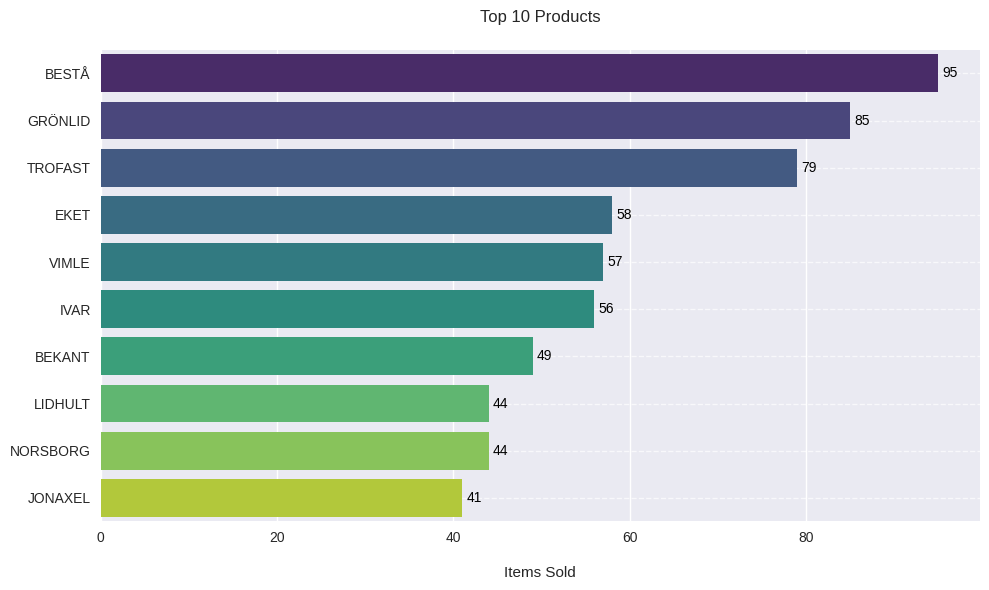

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=product_favorite.head(10),
    x='session_id',
    y='name',
    palette='viridis',
    hue='name',
    ax=ax,
    legend=False
)

plt.title('Top 10 Products', pad=20)
plt.xlabel('Items Sold', labelpad=15)
plt.ylabel('')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()

In [ ]:
#lets calculate daily sales
sales_by_date = data.groupby('session_date')['unit_price'].sum().reset_index()

#visualize it
import plotly.express as px

fig = px.line(
    sales_by_date,
    x='session_date',
    y='unit_price',
    title='Daily Sales Trend:',
    labels={'session_date': '', 'unit_price': 'Total Sales ($)'}
)

fig.update_xaxes(rangeslider_visible=True)
fig.show()

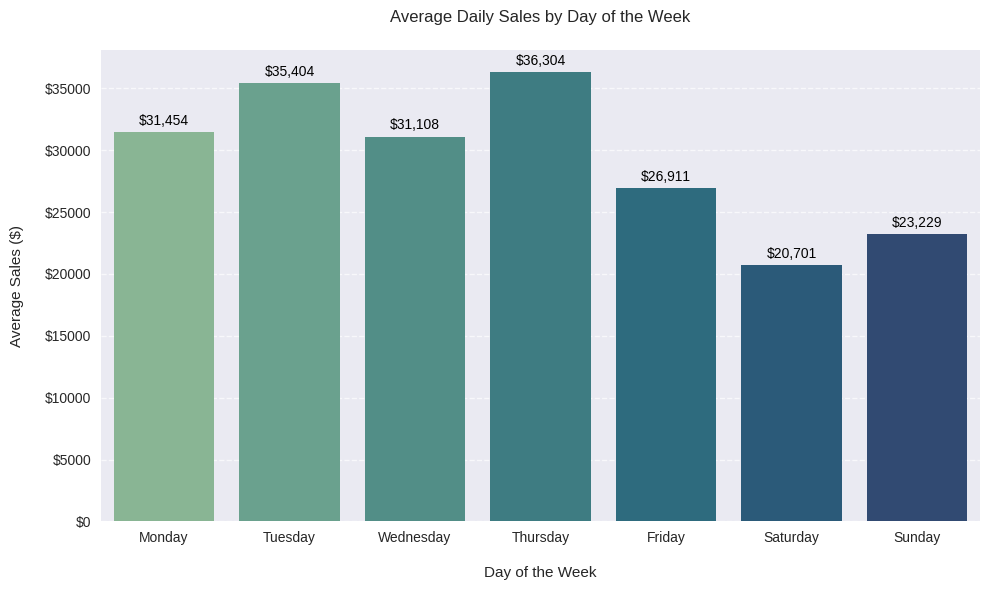

In [ ]:
sales_by_date['day_of_week'] = sales_by_date['session_date'].dt.day_name()

average_sales_by_day = sales_by_date.groupby('day_of_week')['unit_price'].mean().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
]).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=average_sales_by_day,
    x='day_of_week',
    y='unit_price',
    palette='crest',
    hue='day_of_week',
    legend=False
)

plt.title('Average Daily Sales by Day of the Week', pad=20)
plt.xlabel('Day of the Week', labelpad=15)
plt.ylabel('Average Sales ($)', labelpad=15)
formatter = mticker.FormatStrFormatter('$%.0f')
ax.yaxis.set_major_formatter(formatter)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}', padding=3, color='black', fontweight='normal')

plt.tight_layout()
plt.show()

In [ ]:
# Filter data for the specified continents
continents_of_interest = ['Americas', 'Asia', 'Europe']
sales_by_continent_date = data[data['continent'].isin(continents_of_interest)]

# Aggregate daily sales by continent
sales_dynamics = sales_by_continent_date.groupby(['session_date', 'continent'])['unit_price'].sum().reset_index()

# Create an interactive line plot
fig = px.line(
    sales_dynamics,
    x='session_date',
    y='unit_price',
    color='continent',
    title='Daily Sales Dynamics by Continent:',
    labels={'session_date': '', 'unit_price': 'Total Sales ($)', 'continent': 'Continent'},
    line_group='continent', # Ensure separate lines for each continent
    hover_name='continent' # Show continent name on hover
)

fig.update_xaxes(rangeslider_visible=True)
fig.show()

In [ ]:
# Aggregate daily sales by channel
sales_dynamics_by_channel = data.groupby(['session_date', 'channel'])['unit_price'].sum().reset_index()
sales_data = sales_dynamics_by_channel[sales_dynamics_by_channel['channel'] != 'Undefined']



# Create an interactive line plot
fig = px.line(
    sales_data,
    x='session_date',
    y='unit_price',
    color='channel',
    title='Daily Sales Dynamics by Traffic Channel:',
    labels={'session_date': '', 'unit_price': 'Total Sales ($)', 'channel': 'Traffic Channel'},
    line_group='channel', # Ensure separate lines for each channel
    hover_name='channel' # Show channel name on hover
)

fig.update_xaxes(rangeslider_visible=True)
fig.show()

In [ ]:
# Aggregate daily sales by device type
sales_dynamics_by_device = data.groupby(['session_date', 'device'])['unit_price'].sum().reset_index()

# Create an interactive line plot using plotly
fig = px.line(
    sales_dynamics_by_device,
    x='session_date',
    y='unit_price',
    color='device',
    title='Daily Sales Dynamics by Device Type:',
    labels={'session_date': '', 'unit_price': 'Total Sales ($)', 'device': 'Device Type'},
    line_group='device',
    hover_name='device'
)

fig.update_xaxes(rangeslider_visible=True)
fig.show()

### Insights from Daily Sales Dynamics

*   **Regional Trends**: Sales in the **Americas** show the highest volatility with significant peaks, consistently remaining above Asia and Europe. There is a visible upward trend in daily sales starting mid-November.
*   **Channel Performance**: **Organic Search** not only contributes the most in total but also shows the most consistent daily growth. **Paid Search** and **Direct** traffic exhibit similar fluctuating patterns, often peaking simultaneously, suggesting synchronized marketing impact or seasonal shopping behavior.
*   **Device Usage**: **Desktop** sales dynamics are consistently higher and more stable day-to-day compared to mobile. **Mobile** sales show more dramatic spikes on specific days, which might correlate with social media marketing or weekend browsing habits.
*   **Weekly Cycle**: Across almost all dimensions (continents, channels, and devices), there is a recurring 7-day cycle where sales dip significantly every weekend and recover sharply at the start of the work week.

##Lets make some Pivot Tables using Pandas to discover some insights.

In [ ]:
#adding a pivot table that shows the number of sessions by traffic channels and device types

channel_device_pivot = data.pivot_table(
    index='channel',
    columns='device',
    values='session_id',
    aggfunc='count'
).sort_values(by='desktop', ascending=False)
channel_device_pivot.head(4)

device,desktop,mobile,tablet
channel,,,
Organic Search,589,407,20
Paid Search,390,299,17
Direct,388,236,12
Social Search,130,101,7


In [ ]:
#total sales by top-10 categories and top-5 countries

sales_category_pivot = data.pivot_table(
    index='country',
    columns='category',
    values='unit_price',
    aggfunc='sum',
    fill_value=0,
)

# Calculate total sales for each category across all countries
category_total_sales = sales_category_pivot.sum(axis=0).sort_values(ascending=False).head(10)

# Reorder the columns of the pivot table based on total sales of categories
sales_category_pivot = sales_category_pivot[category_total_sales.index]

# Keep the 'Total' column for country-wise sum if needed, or remove if only category sorting is desired
sales_category_pivot['Total'] = sales_category_pivot.sum(axis=1)
sales_category_pivot.sort_values(by='Total', ascending=False).head()

category,Sofas & armchairs,Chairs,Beds,Bookcases & shelving units,Cabinets & cupboards,Tables & desks,Outdoor furniture,Chests of drawers & drawer units,Bar furniture,Children's furniture,Total
country,,,,,,,,,,,
United States,301810.5,217604.4,159607.5,104166.9,86776.5,81323.5,59765.0,23080.5,26343.0,24092.0,1084569.8
India,49474.5,49072.2,20160.0,29394.4,17447.0,8698.0,16364.4,7922.0,503.0,4601.0,203636.5
Canada,55946.0,22841.4,40796.0,17364.0,22746.0,15144.0,1795.0,3640.0,3763.0,3362.0,187397.4
United Kingdom,10578.0,16528.0,11850.0,6311.0,7574.5,4870.0,1982.0,881.0,2561.0,1135.0,64270.5
Singapore,28049.0,10810.0,6939.0,5078.0,8750.0,0.0,3016.8,0.0,129.0,304.0,63075.8


In [ ]:
#Lets find some Bestsellers.

bestselling_products = data.pivot_table(
    index='name',
    values=['session_id', 'unit_price'],
    aggfunc={'session_id': 'count', 'unit_price': 'sum'}
).sort_values(by='session_id', ascending=False)

# Calculate percentage of total revenue
total_sales_overall = data['unit_price'].sum()
bestselling_products['per_of_ttl'] = (bestselling_products['unit_price'] / total_sales_overall * 100).round(2)

renamed_columns = {
    'session_id': 'Items Sold',
    'unit_price': 'Total Revenue',
    'per_of_ttl': '% of Total Revenue'
}
bestselling_products_renamed = bestselling_products.rename(columns=renamed_columns)

bestselling_products_renamed.head(10)


,Items Sold,Total Revenue,% of Total Revenue
name,,,
BESTÅ,95,76794.0,2.97
GRÖNLID,85,220735.0,8.55
TROFAST,79,16965.0,0.66
EKET,58,26872.0,1.04
VIMLE,57,140335.0,5.43
IVAR,56,41930.0,1.62
BEKANT,49,82448.0,3.19
LIDHULT,44,182665.0,7.07
NORSBORG,44,57580.0,2.23


In [ ]:
#Which OS customers use the most.

os_pivot = data.pivot_table(
    index='operating_system',
    values=['session_id', 'unit_price'],
    aggfunc={'session_id':'count', 'unit_price': 'sum'},
    fill_value=0,
).sort_values(by='session_id', ascending=False)

renamed_columns = {
    'session_id': 'Items Sold',
    'unit_price': 'Total Revenue',
}
os_pivot_renamed = os_pivot.rename(columns=renamed_columns)

os_pivot_renamed.head(5)

,Items Sold,Total Revenue
operating_system,,
Web,1634,1592862.5
Windows,341,270490.7
iOS,329,289913.1
Android,220,198344.7
Macintosh,188,181545.5


## Now I will calculate correlation and statistical significance.

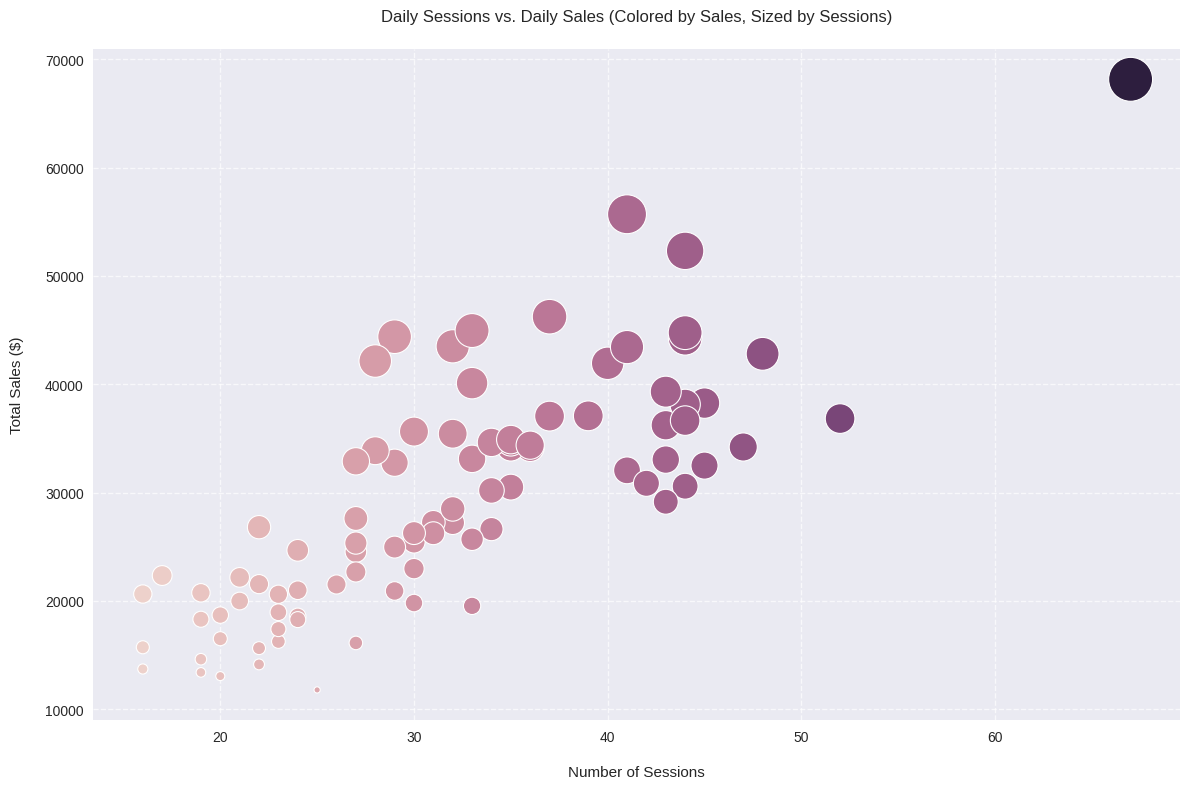

In [ ]:
#count of sessions and total sales per date
count_sales_by_date = data.groupby(
    'session_date').agg(
        {'session_id': 'count', 'unit_price': 'sum'}).reset_index().sort_values(by='session_date', ascending=False)

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=count_sales_by_date,
    x='session_id',
    y='unit_price',
    hue='session_id',
    size='unit_price',
    sizes=(20, 1000),
    legend=False,
    )
plt.title('Daily Sessions vs. Daily Sales (Colored by Sales, Sized by Sessions)', pad=20)
plt.xlabel('Number of Sessions', labelpad=15)
plt.ylabel('Total Sales ($)', labelpad=15)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
#correlation coefficient and statiatical significance
from scipy.stats import pearsonr

correlation_coefficient, p_value = pearsonr(count_sales_by_date['session_id'], count_sales_by_date['unit_price'])

print(f"Pearson Correlation Coefficient: {correlation_coefficient:.2f}")
print(f"P-value: {p_value:.3f}")

if p_value < 0.05:
    print("The correlation is statistically significant (p < 0.05).")
else:
    print("The correlation is not statistically significant (p >= 0.05).")

Pearson Correlation Coefficient: 0.80
P-value: 0.000
The correlation is statistically significant (p < 0.05).


In [ ]:
#correlation on top-3 continents by sales
sales_pivot = data.pivot_table(
    index='session_date',
    columns='continent',
    values='unit_price',
    aggfunc='sum',
)

# find out top-3 continents by sales
total_sales = sales_pivot.sum(axis=0).sort_values(ascending=False).head(3)
sales_pivot = sales_pivot[total_sales.index]

#correlation and p-value
from itertools import combinations
from scipy.stats import pearsonr

for c1, c2 in combinations(sales_pivot.columns, 2):
    corr, p = pearsonr(sales_pivot[c1], sales_pivot[c2])
    print(f"{c1} vs {c2}: corr={corr:.2f}, p={p:.3f}")

Americas vs Asia: corr=0.24, p=0.025
Americas vs Europe: corr=0.09, p=0.415
Asia vs Europe: corr=0.09, p=0.395


*According to previous calculations i got weak positive correlation with statistical significant result between America and Asia continent.*

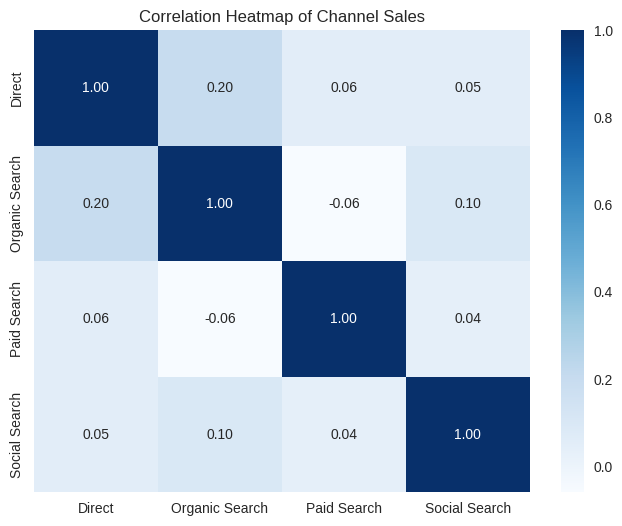

,Chanel 1,Chanel 2,Correlation,P-value,Significant (p < 0.05)
0,Direct,Organic Search,0.199,0.0637,False
4,Organic Search,Social Search,0.101,0.3511,False
3,Organic Search,Paid Search,-0.060,0.5793,False
1,Direct,Paid Search,0.056,0.6049,False
2,Direct,Social Search,0.053,0.6248,False
5,Paid Search,Social Search,0.038,0.7261,False


In [ ]:
#daily sales correlation between traffic channels.


daily_channel_sales = data.pivot_table(
    index='session_date',
    columns='channel',
    values='unit_price',
    aggfunc='sum',
    fill_value=0
)

#remove undefined
if 'Undefined' in daily_channel_sales.columns:
    daily_channel_sales = daily_channel_sales.drop(columns=['Undefined'])


channel_corr = daily_channel_sales.corr()

#visualization for better experince
plt.figure(figsize=(8, 6))
sns.heatmap(channel_corr, annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap of Channel Sales')
plt.xlabel('')
plt.ylabel('')


plt.show()

# Using the pivot table created earlier
channel_names = daily_channel_sales.columns
channel_results = []

# Iterate through each pair of channels to calculate correlation and p-value
for i in range(len(channel_names)):
    for j in range(i + 1, len(channel_names)):
        ch1, ch2 = channel_names[i], channel_names[j]
        corr, p_val = pearsonr(daily_channel_sales[ch1], daily_channel_sales[ch2])
        channel_results.append({
            'Chanel 1': ch1,
            'Chanel 2': ch2,
            'Correlation': round(corr, 3),
            'P-value': round(p_val, 4),
            'Significant (p < 0.05)': p_val < 0.05
        })

channels_df = pd.DataFrame(channel_results)
display(channels_df.sort_values(by='P-value'))


*We spot weak positive and negative correlations, which is good. Unfortunately, these results aren't statistically significant, so the correlation results are inappropriate.*

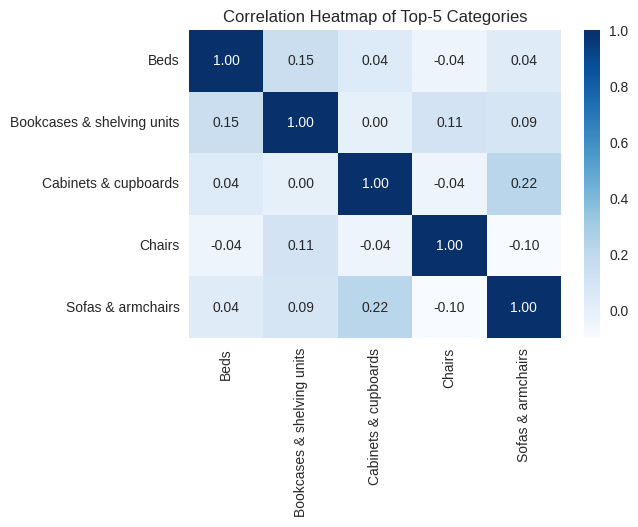

,Category 1,Category 2,Correlation,P-value,Significant (p < 0.05)
8,Cabinets & cupboards,Sofas & armchairs,0.220,0.0392,True
0,Beds,Bookcases & shelving units,0.153,0.1547,False
5,Bookcases & shelving units,Chairs,0.107,0.3204,False
9,Chairs,Sofas & armchairs,-0.098,0.3641,False
6,Bookcases & shelving units,Sofas & armchairs,0.088,0.4145,False
1,Beds,Cabinets & cupboards,0.045,0.6775,False
7,Cabinets & cupboards,Chairs,-0.040,0.7116,False
2,Beds,Chairs,-0.040,0.7117,False
3,Beds,Sofas & armchairs,0.036,0.7362,False
4,Bookcases & shelving units,Cabinets & cupboards,0.000,0.9993,False


In [ ]:
#sales correlation in top-5 categories.

#top-5 categories calculation
top_5_categories = data.groupby('category')['unit_price'].sum().sort_values(ascending=False).head(5).index

#create the pivot table filtered for these top 5 categories
sales_categories_pivot = data[data['category'].isin(top_5_categories)].pivot_table(
    index='session_date',
    columns='category',
    values='unit_price',
    aggfunc='sum',
    fill_value=0
)

#calculate correlation between these top categories
sales_categories_corr = sales_categories_pivot.corr()


#visualization for better experince
plt.figure(figsize=(6, 4))
sns.heatmap(sales_categories_corr, annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap of Top-5 Categories')
plt.xlabel('')
plt.ylabel('')


plt.show()

# Using the pivot table created earlier
categories_names = sales_categories_pivot.columns
categories_results = []

# Iterate through each pair of categories to calculate correlation and p-value
for i in range(len(categories_names)):
    for j in range(i + 1, len(categories_names)):
        c1, c2 = categories_names[i], categories_names[j]
        corr, p_val = pearsonr(sales_categories_pivot[c1], sales_categories_pivot[c2])
        categories_results.append({
            'Category 1': c1,
            'Category 2': c2,
            'Correlation': round(corr, 3),
            'P-value': round(p_val, 4),
            'Significant (p < 0.05)': p_val < 0.05
        })

categories_products_df = pd.DataFrame(categories_results)
display(categories_products_df.sort_values(by='P-value'))

*Only one weak positive correlation shows us a statistically significant result, which is better than nothing.*

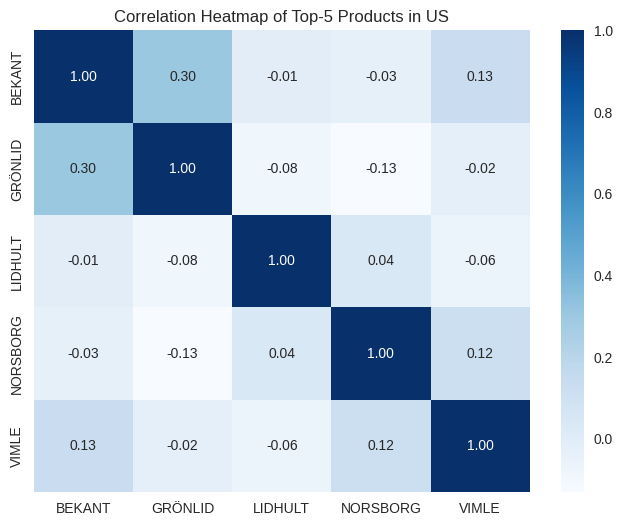

,Product 1,Product 2,Correlation,P-value,Significant (p < 0.05)
0,BEKANT,GRÖNLID,0.302,0.0052,True
3,BEKANT,VIMLE,0.134,0.2250,False
5,GRÖNLID,NORSBORG,-0.131,0.2350,False
9,NORSBORG,VIMLE,0.118,0.2831,False
4,GRÖNLID,LIDHULT,-0.083,0.4515,False
8,LIDHULT,VIMLE,-0.063,0.5715,False
7,LIDHULT,NORSBORG,0.040,0.7199,False
2,BEKANT,NORSBORG,-0.031,0.7790,False
6,GRÖNLID,VIMLE,-0.022,0.8440,False
1,BEKANT,LIDHULT,-0.009,0.9388,False


In [ ]:
#sales correlation between top-5 products in the US.
country_sales = data[data['country'] == 'United States'].groupby(
    'name')['unit_price'].sum().sort_values(ascending=False).head(5).index

product_country_pivot = data[data['name'].isin(country_sales)].pivot_table(
    index='session_date',
    columns='name',
    values='unit_price',
    aggfunc='sum',
    fill_value=0
)

prod_corr = product_country_pivot.corr()


#visualization for better experince
plt.figure(figsize=(8, 6))
sns.heatmap(prod_corr, annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap of Top-5 Products in US')
plt.xlabel('')
plt.ylabel('')


plt.show()

# Using the product_country_pivot table for top 5 US products created earlier
product_names = product_country_pivot.columns
us_prod_results = []

# Iterate through each pair of products to calculate correlation and p-value
for i in range(len(product_names)):
    for j in range(i + 1, len(product_names)):
        p1, p2 = product_names[i], product_names[j]
        corr, p_val = pearsonr(product_country_pivot[p1], product_country_pivot[p2])
        us_prod_results.append({
            'Product 1': p1,
            'Product 2': p2,
            'Correlation': round(corr, 3),
            'P-value': round(p_val, 4),
            'Significant (p < 0.05)': p_val < 0.05
        })

sig_us_products_df = pd.DataFrame(us_prod_results)
display(sig_us_products_df.sort_values(by='P-value'))

*Again, we can see only one statistical significance for a weak positive correlation.*

In [ ]:
# daily sales for subscribed and unsubscribed users
sales_by_user_status = data.pivot_table(
    index='session_date',
    columns='is_unsubscribed',
    values='unit_price',
    aggfunc='sum',
    fill_value=0
).rename(columns={0: 'Subscribed', 1: 'Unsubscribed'})

# Calculate totals
totals = sales_by_user_status.sum().to_frame(name='Total Sales')
display(totals)

display(sales_by_user_status.head())

from scipy.stats import shapiro, ttest_ind
# Normality test
_, p_value_norm_group_1 = shapiro(sales_by_user_status['Subscribed'])
_, p_value_norm_group_2 = shapiro(sales_by_user_status['Unsubscribed'])
print(f"p-value of normality test for Group 1: {p_value_norm_group_1}")
print(f"p-value of normality test for Group 2: {p_value_norm_group_2}")

# Perform t-test
t_stat, p_value = ttest_ind(sales_by_user_status['Subscribed'], sales_by_user_status['Unsubscribed'])
print(f"t-statistic: {t_stat}, p-value: {p_value}")


,Total Sales
is_unsubscribed,
Subscribed,2150796.9
Unsubscribed,431721.6


is_unsubscribed,Subscribed,Unsubscribed
session_date,,
2020-11-01,17288.0,4259.0
2020-11-02,35576.8,9380.0
2020-11-03,21391.5,7759.0
2020-11-04,17107.2,3875.0
2020-11-05,24158.6,1176.0


p-value of normality test for Group 1: 0.0018539954208119539
p-value of normality test for Group 2: 4.0876403097868696e-08
t-statistic: 17.454892787345702, p-value: 4.3865291200503915e-40


*In conclusion, we received a statistically significant result, which means that the group with the highest total sales amount will take the lead. In our case, subscribed users bring us more money.*

In [ ]:
from scipy.stats import f_oneway

session_count_channel = data.pivot_table(
    index='session_date',
    columns='channel',
    values='session_id',
    aggfunc='count',
    fill_value=0
)

session_channel_data = session_count_channel.drop(columns=['Undefined'], errors='ignore')

# Calculate totals
totals = session_channel_data.sum().to_frame(name='Total Sales')
display(totals)

display(session_channel_data.head())

#using ANOVA, because of four groups.
f_stat, p_value = f_oneway(
    session_channel_data['Direct'],
    session_channel_data['Organic Search'],
    session_channel_data['Paid Search'],
    session_channel_data['Social Search']
)

print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.4f}")

# Interpretation
if p_value < 0.05:
    print("There is a statistically significant difference between the campaigns.")
else:
    print("No statistically significant difference found between the campaigns.")

,Total Sales
channel,
Direct,636
Organic Search,1016
Paid Search,706
Social Search,238


channel,Direct,Organic Search,Paid Search,Social Search
session_date,,,,
2020-11-01,5,10,5,2
2020-11-02,9,11,8,1
2020-11-03,10,9,15,3
2020-11-04,7,10,5,0
2020-11-05,8,9,4,3


F-statistic: 94.9254
P-value: 0.0000
There is a statistically significant difference between the campaigns.


We received a statistically significant result, which means that the group with the highest sessions amount will take the lead. In our case, Organic Search is the most relevant traffic channel.

In [ ]:
# Defining specific continents for comparison
selected_continents = ['Americas', 'Europe']

# Pivot table for sessions count by date, channel and continent
continents_pivot = data[data['continent'].isin(selected_continents)].pivot_table(
    index='session_date',
    columns=['channel', 'continent'],
    values='session_id',
    aggfunc='count',
    fill_value=0
)

# Filter for Organic Search channel only
organic_data = continents_pivot['Organic Search']

# Calculate totals for quick overview
totals = organic_data.sum().to_frame(name='Total Sessions')
display(totals)
display(organic_data.head())

# Normality test (Shapiro-Wilk)
_, p_norm_1 = shapiro(organic_data['Americas'])
_, p_norm_2 = shapiro(organic_data['Europe'])

print(f"p-value for Americas: {p_norm_1:.4f}")
print(f"p-value for Europe: {p_norm_2:.4f}")

# T-test for independent samples
t_stat, p_val = ttest_ind(organic_data['Americas'], organic_data['Europe'])
print(f"t-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")

if p_val < 0.05:
    print("Difference between Americas and Europe is statistically significant.")
else:
    print("No Statistical Significance found.")

,Total Sessions
continent,
Americas,562
Europe,180


continent,Americas,Europe
session_date,,
2020-11-01,8,2
2020-11-02,7,2
2020-11-03,7,0
2020-11-04,4,3
2020-11-05,5,1


p-value for Americas: 0.0019
p-value for Europe: 0.0000
t-statistic: 12.6280, p-value: 0.0000
Difference between Americas and Europe is statistically significant.
